# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

## Setup

In [1]:
import os

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline
%aimport lassi.get_power
%aimport lassi.argostream_curl

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [2]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs [""]
    
    """

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    """
    source_folder = "HeCBench"  # "altis/src/cuda/level1"
    app_folder_name = "lid-driven-cavity"  # "bfs"
    build_script = False  # False (for HeCBench)

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_folder_name
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_60 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    model = "gpto1preview"  # (max token = 128000)
    model_coder = "gpt4o"  # (max token = 128000)
    # model = "gpto1preview"  # (max token = 128000)

    # -- FROM OLLAMA
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 128000

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "04test_o1p_ee_hecbench"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder, llm_source, use_context,
            context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Application: lid-driven-cavity

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto1preview
Model coder: gpt4o
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto1preview/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp04test_o1p_ee_hecbench

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

LLM Prompt for Code Generation: 

Carefully follow all these instructions step-by-step: 
STEP 1. Read the background knowledge and your background knowledge summaries about programming and energy-efficiency strategies. 
STEP 2. Read your description and analysis of th

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: source_codes/HeCBench/lid-driven-cavity
Execute command: ['./lid-driven-cavity-cuda_main', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 88410, res = 9.999561e-04
Time = 0.001000, delt = 4.632568e-05, iter = 86674, res = 9.999808e-04

Total execution time of the iteration loop: 21.065119 (s)
GPU power data has been written to source_CUDA_gpu_power_results.csv


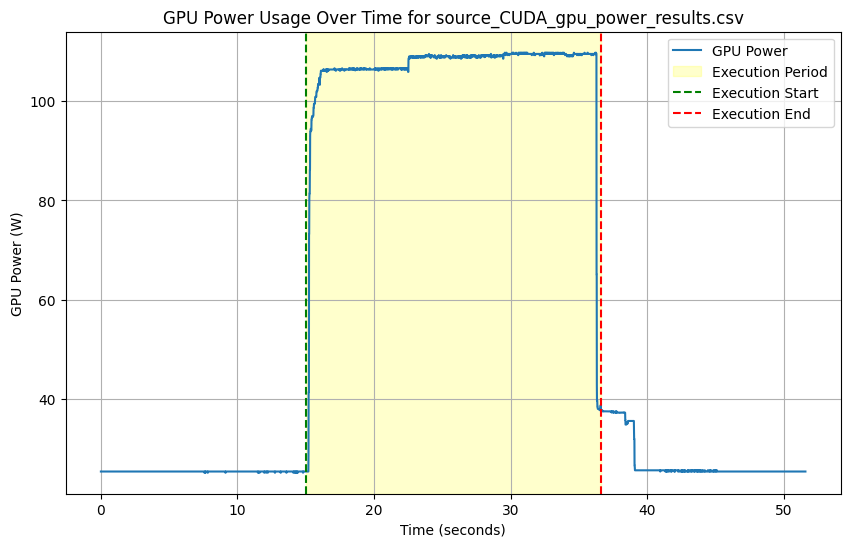

Start time: 15.001 -- End time: 36.586

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 21.59 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000639 kWh
  0.6391 Wh
  2300.62 J
Average GPU power: 106.60 W
Total Energy During Exe Runtime:   2300.62 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 21.59
GPU power data has been written to idle__gpu_power_results.csv


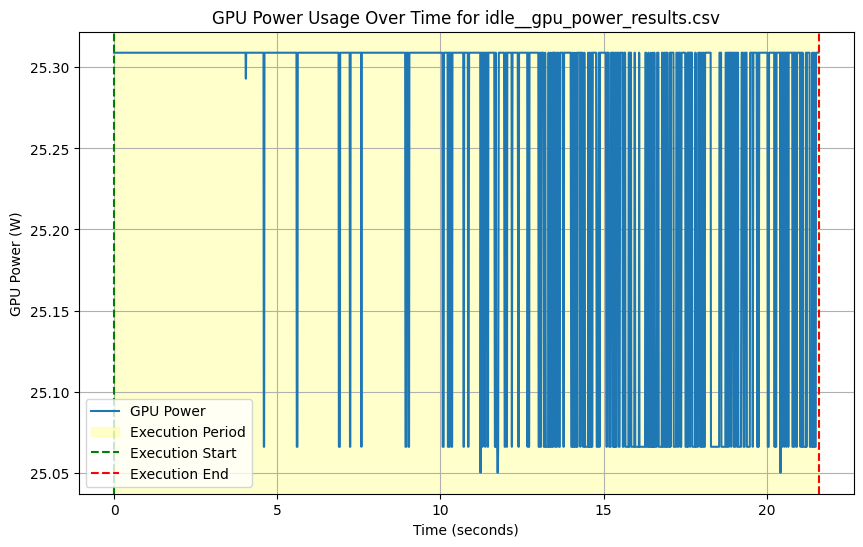

Start time: 0 -- End time: 21.586

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 21.59 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000151 kWh
  0.1515 Wh
  545.37 J
Average GPU power: 25.26 W
Total Energy During Exe Runtime:   545.37 J
----------------------------------------------------------------------------------------------------------------------------------------





----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----


GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269 MiB free, 16384 MiB total

--> ... prompt LLM to summarize context knowledge.
**Summary of Key Relevant Points for Refactoring CUDA C++ Code to Improve Energy Efficiency**

To refactor CUDA C++ code for improved energy efficiency—aiming to reduce both GPU and CPU power consumption while maintaining functionality—we should apply the following key best practices derived from the pr

**Summary of Key Relevant Points for Refactoring CUDA C++ Code to Improve Energy Efficiency**

To refactor CUDA C++ code for improved energy efficiency—aiming to reduce both GPU and CPU power consumption while maintaining functionality—we should apply the following key best practices derived from the provided background documents:

1. **Minimize Data Transfers Between Host and Device (High Priority):**
   - **Avoid Unnecessary Transfers:**
     - Reduce the frequency and volume of data transfers between the CPU (host) and GPU (device), as they are costly in terms of both time and energy.
     - Keep data resident on the device by creating and manipulating intermediate data structures entirely in device memory without copying them to host memory.
   - **Batch Small Transfers:**
     - Combine many small data transfers into larger, batched transfers to reduce overhead and improve transfer efficiency.
     - This may involve packing non-contiguous memory regions into a contiguous buffer before transfer and unpacking afterward.
   - **Use Page-Locked (Pinned) Memory:**
     - Employ page-locked host memory to achieve higher bandwidth during data transfers between host and device.
     - Pinned memory reduces transfer latency and power consumption due to more efficient use of PCIe bandwidth.

2. **Optimize Memory Access Patterns (High Priority):**
   - **Prefer Shared Memory Over Global Memory:**
     - Utilize shared memory for data that is reused within a thread block to take advantage of its low latency and high bandwidth, reducing reliance on slower global memory.
     - Minimizing global memory accesses lowers memory latency and energy consumption.
   - **Coalesce Global Memory Accesses:**
     - Arrange memory accesses so that threads within a warp access consecutive memory addresses, enabling memory coalescing and improving memory throughput.
   - **Avoid Bank Conflicts in Shared Memory:**
     - Organize shared memory accesses to prevent multiple threads from accessing the same memory bank simultaneously, thus maintaining high memory bandwidth.

3. **Maintain High Occupancy and Parallelism (Medium Priority):**
   - **Maximize Active Threads per Multiprocessor:**
     - Ensure sufficient threads are active to hide memory latency through context switching, keeping GPU execution units busy and reducing idle power consumption.
   - **Use Appropriate Block and Grid Dimensions:**
     - Configure thread blocks with a number of threads that is a multiple of the warp size (32 threads) to optimize hardware utilization.
     - Balance block sizes to match the GPU architecture, promoting efficient scheduling and resource utilization.
   - **Avoid Register Starvation:**
     - Optimize kernel code to use registers efficiently, preventing excessive spilling to local memory, which can increase memory traffic and energy use.

4. **Reduce Warp Divergence (High Priority):**
   - **Avoid Divergent Branching:**
     - Structure code to minimize conditional branches that cause threads within a warp to follow different execution paths, leading to serialization and reduced efficiency.
     - When conditional statements are necessary, align them with warp boundaries to prevent divergence within warps.
   - **Use Predication When Appropriate:**
     - Leverage the compiler's ability to use predication for short conditional code paths, eliminating actual branches and maintaining warp convergence.

5. **Utilize Fast Math Libraries and Specialized Functions (Medium Priority):**
   - **Employ Fast Math Functions:**
     - Use the fast math library functions (e.g., `__sinf()`, `__expf()`) when reduced precision is acceptable, as they execute more quickly and consume less energy.
     - Be cautious of the trade-off between precision and performance to ensure application correctness.
   - **Prefer Specialized Over General Math Functions:**
     - Replace general functions like `pow()` with specialized versions like `exp2()`, `exp10()`, `cbrt()`, and `rcbrt()` for common exponentials and roots for better performance and energy efficiency.
   - **Use Efficient Constants and Operations:**
     - Define floating-point constants with the correct precision suffix (e.g., `1.0f` for single-precision) to prevent unnecessary type conversions.
     - Replace expensive operations like integer division and modulo with bitwise operations when operands are powers of two.

6. **Optimize Thread Synchronization and Communication:**
   - **Use Intra-Block Communication Efficiently:**
     - Leverage shared memory and synchronization primitives like `__syncthreads()` within a block to coordinate threads without incurring the overhead of global memory accesses.
   - **Minimize Synchronization Overhead:**
     - Avoid excessive synchronization that can stall threads and decrease occupancy, leading to increased energy consumption.

7. **Leverage Newer Architectural Features:**
   - **Utilize Asynchronous Operations and Pipelines:**
     - Employ asynchronous data transfers and compute overlaps using streams and the `cudaMemcpyAsync()` function to keep the GPU busy and reduce idle times.
     - Use `cuda::pipeline` and thread scope synchronization (`cuda::thread_scope_block`) to optimize data movement and synchronization at fine granularities.
   - **Consider Thread Block Clusters (If Available):**
     - On GPUs that support thread block clusters, organize thread blocks to exploit high-bandwidth memory access and synchronization features within clusters.

8. **Efficient Use of Data Types and Precision:**
   - **Use Appropriate Precision:**
     - Opt for single-precision (`float`) over double-precision (`double`) when higher precision is not required, as single-precision operations are faster and consume less energy.
   - **Prefer Signed Integers for Loop Counters (Low Medium Priority):**
     - Use signed integers for loop counters to enable more aggressive compiler optimizations, potentially reducing instruction counts and energy usage.

9. **Reduce CPU-side Overhead:**
   - **Launch Kernels Efficiently:**
     - Minimize CPU-GPU synchronization points and kernel launch overhead by batching small workloads into larger kernels when possible.
   - **Overlap CPU and GPU Work:**
     - While the GPU is executing kernels, perform other CPU-side computations or preparations to maximize overall system utilization.

10. **Code Refactoring for Compiler Optimizations:**
    - **Facilitate Loop Unrolling and Inlining:**
      - Write code in a way that allows the compiler to unroll loops and inline functions where beneficial, reducing control overhead and potentially lowering energy consumption.
    - **Avoid Excessive Use of Templates and Virtual Functions:**
      - Simplify code to help the compiler generate efficient machine code without excessive abstraction penalties.

By incorporating these best practices into the refactored code, we can achieve improved energy efficiency through:

- **Reduced Data Movement:** Minimizing costly data transfers saves energy and time.
- **Enhanced Parallel Efficiency:** Maximizing occupancy and minimizing divergence leads to better utilization of GPU resources.
- **Optimized Memory Usage:** Efficient memory access patterns reduce latency and power draw from memory subsystems.
- **Accelerated Computations:** Using faster math functions and optimizing code paths decreases execution time and energy consumption.
- **Balanced Workload Distribution:** Keeping both CPU and GPU effectively engaged avoids idle periods and spreads power consumption more evenly.

**Conclusion**

Applying these key points during refactoring will help us optimize the CUDA C++ code to be more energy-efficient while maintaining its original functionality. By focusing on minimizing data transfers, optimizing memory access, maintaining high occupancy, reducing warp divergence, and leveraging fast math operations, we can significantly reduce both GPU and CPU power consumption.

GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269 MiB free, 16384 MiB total

--> ... prompt LLM to describe the source code.
**Description and Analysis:**

The provided CUDA C++ code is a GPU-based solver for the **2D lid-driven cavity problem**, which is a classical fluid dynamics benchmark problem. The code solves the incompressible, isothermal Navier–Stokes equations using the finite difference method on a staggered grid. The solver incorporates techniques like Red-Black Gauss-Seidel iteration with Successive Over-Relaxation (SOR) for solving the pressure Poisson equation, and handles dynamic time-stepping based on the Courant-Friedrichs-Lewy (CFL) condition.

**Major Data Structures:**

1. **Data Types and Constants:**
   - `Real`: Defined as `double` precision floating-point number due to `#define DOUBLE`. It can switch to `float` if `DOUBLE` is not defined.
   - **Simulation Constants:**
     - `Re_num`: Reynolds number, set to 1

**Description and Analysis:**

The provided CUDA C++ code is a GPU-based solver for the **2D lid-driven cavity problem**, which is a classical fluid dynamics benchmark problem. The code solves the incompressible, isothermal Navier–Stokes equations using the finite difference method on a staggered grid. The solver incorporates techniques like Red-Black Gauss-Seidel iteration with Successive Over-Relaxation (SOR) for solving the pressure Poisson equation, and handles dynamic time-stepping based on the Courant-Friedrichs-Lewy (CFL) condition.

**Major Data Structures:**

1. **Data Types and Constants:**
   - `Real`: Defined as `double` precision floating-point number due to `#define DOUBLE`. It can switch to `float` if `DOUBLE` is not defined.
   - **Simulation Constants:**
     - `Re_num`: Reynolds number, set to 1000.0.
     - `omega`: SOR relaxation parameter, set to 1.7.
     - `mix_param`: Discretization mixture parameter (γ), set to 0.9.
     - `tau`: Safety factor for time step modification, set to 0.5.
     - `gx`, `gy`: Body forces in the x and y directions, both set to 0.0.
     - `xLength`, `yLength`: Non-dimensional domain sizes, both set to 1.0.
     - `dx`, `dy`: Mesh sizes calculated as `xLength / NUM` and `yLength / NUM` respectively.
   - **Numerical Constants:**
     - `ZERO`, `ONE`, `TWO`, `FOUR`: Numeric constants for convenience.
     - `SMALL`: Small number (1.0e-10) used to prevent division by zero or as an initial minimum value.

2. **Grid Definition:**
   - `NUM`: Number of grid cells along one axis; total grid cells are `NUM × NUM`. Defined as 512.
   - **Index Mapping Macros:**
     - Macros like `u(I, J)`, `v(I, J)`, `F(I, J)`, `G(I, J)`, `pres_red(I, J)`, and `pres_black(I, J)` map 2D indices `(I, J)` to 1D array indices to facilitate linear storage of 2D grid data.

3. **Arrays for Flow Variables:**
   - **Velocity Fields:**
     - `u`: x-component of velocity, size `(NUM + 2) × (NUM + 2)` to include ghost cells for boundary conditions.
     - `v`: y-component of velocity, same size as `u`.
   - **Intermediate Velocity Fields:**
     - `F`: Intermediate x-velocity (used in predictor step), same size as `u`.
     - `G`: Intermediate y-velocity, same size as `v`.
   - **Pressure Fields:**
     - `pres_red`, `pres_black`: Pressure values on red and black grid points for the Red-Black Gauss-Seidel method. Size depends on half the number of grid cells due to checkerboard coloring.

4. **Auxiliary Arrays:**
   - `res`: Stores residuals of the pressure field to check for convergence.
   - `max_u_arr`, `max_v_arr`: Store maximum velocities in each block for dynamic time-stepping.
   - `pres_sum`: Stores sums of pressure values to compute norms.

**Major Functions and Kernels:**

1. **Boundary Condition Functions:**
   - `set_BCs_host (Real* u, Real* v)`: Host function that initializes the velocity fields `u` and `v` with boundary conditions before the GPU computation begins.
   - `set_BCs (Real* u, Real* v)`: GPU kernel that updates velocity boundary conditions during the simulation.

2. **Intermediate Velocity Calculation Kernels:**
   - `calculate_F (Real dt, const Real* u, const Real* v, Real* F)`: Computes intermediate x-velocity `F` using finite difference approximations for the convection and diffusion terms of the momentum equations.
   - `calculate_G (Real dt, const Real* u, const Real* v, Real* G)`: Computes intermediate y-velocity `G` similarly to `calculate_F`.

3. **Pressure Solver Kernels:**
   - `sum_pressure (const Real* pres_red, const Real* pres_black, Real* pres_sum)`: Computes the sum of squares of pressure values to calculate the initial pressure norm used for convergence checking.
   - `set_horz_pres_BCs (Real* pres_red, Real* pres_black)`: Sets horizontal boundary conditions for pressure fields.
   - `set_vert_pres_BCs (Real* pres_red, Real* pres_black)`: Sets vertical boundary conditions for pressure fields.
   - `red_kernel (Real dt, const Real* F, const Real* G, const Real* pres_black, Real* pres_red)`: Updates red pressure points in the Red-Black Gauss-Seidel method.
   - `black_kernel (Real dt, const Real* F, const Real* G, const Real* pres_red, Real* pres_black)`: Updates black pressure points similarly to `red_kernel`.
   - `calc_residual (Real dt, const Real* F, const Real* G, const Real* pres_red, const Real* pres_black, Real* res_array)`: Computes the residuals of the pressure field to determine convergence of the pressure solver.

4. **Velocity Update Kernels:**
   - `calculate_u (Real dt, const Real* F, const Real* pres_red, const Real* pres_black, Real* u, Real* max_u)`: Updates the x-component of velocity `u` using the pressure gradient and computes the maximum `u` value in each block.
   - `calculate_v (Real dt, const Real* G, const Real* pres_red, const Real* pres_black, Real* v, Real* max_v)`: Updates the y-component of velocity `v` similarly to `calculate_u`.

5. **Main Function (`int main (int argc, char *argv[])`):**
   - **Initialization:**
     - Allocates memory for all arrays on the host.
     - Initializes boundary conditions and variables.
     - Computes initial maximum velocities for time-stepping.
   - **Memory Allocation on Device:**
     - Allocates corresponding memory on the GPU for all necessary arrays.
     - Copies initialized data from host to device.
   - **Time-Stepping Loop:**
     - **Time Step Calculation:**
       - Computes `dt` based on the CFL condition and maximum velocities to ensure numerical stability.
     - **Predictor Step (Intermediate Velocities):**
       - Calls `calculate_F` and `calculate_G` kernels to compute intermediate velocities.
     - **Pressure Solver:**
       - Computes the initial pressure norm using `sum_pressure`.
       - Enters an iteration loop using the Red-Black Gauss-Seidel method with SOR:
         - Sets pressure boundary conditions using `set_horz_pres_BCs` and `set_vert_pres_BCs`.
         - Updates red and black pressure points using `red_kernel` and `black_kernel`.
         - Computes residuals using `calc_residual`.
         - Checks for convergence against a specified tolerance.
     - **Corrector Step (Velocity Update):**
       - Updates velocities `u` and `v` using `calculate_u` and `calculate_v`.
       - Computes maximum velocities in each block for the next time step calculation.
     - **Boundary Conditions and Time Advancement:**
       - Updates velocity boundary conditions using `set_BCs`.
       - Advances simulation time by `dt`.
     - **Output:**
       - Prints simulation progress, including time, time step size, iteration count, and residual norm.
   - **Post-Processing:**
     - Copies final results back to the host.
     - Writes velocity field data to an output file `velocity_gpu.dat`.
     - Frees allocated device and host memory.

**Algorithm Overview:**

- **Numerical Method:**
  - Uses finite difference discretization on a staggered grid for the spatial derivatives in the Navier-Stokes equations.
  - Employs the Red-Black Gauss-Seidel method with SOR for solving the pressure Poisson equation, which is suitable for parallelization.
  - Time integration is performed using an explicit method, with dynamic time stepping based on the CFL condition.

- **Parallelization Strategy:**
  - **Kernels**: Compute-intensive portions are implemented as CUDA kernels to run on the GPU.
  - **Thread Management**: Grids and blocks are configured to maximize occupancy and utilize the GPU efficiently.
  - **Shared Memory**: Used within kernels for intermediate computations and reductions, improving memory access times.
  - **Data Transfer**: Minimizes data transfer between host and device by performing most calculations on the device.

- **Boundary Conditions:**
  - Velocity boundary conditions enforce the lid-driven cavity scenario, with the top lid moving at a constant speed and no-slip conditions on other walls.
  - Pressure boundary conditions are set to ensure continuity and compatibility with the velocity field.

**Convergence and Stability:**

- **Residual Computation:**
  - Residuals of the pressure field are computed to monitor convergence within the SOR iterations.
  - Convergence is achieved when the normalized L2 norm of the residuals falls below a specified tolerance (`tol`).

- **Time Step Control:**
  - The time step `dt` is adjusted dynamically based on the maximum velocities and the Reynolds number to satisfy stability criteria.
  - The safety factor `tau` ensures that the time step is within stable limits.

**Output and Results:**

- **Reporting:**
  - The simulation progress is printed to the console, including the current simulation time, time step size, iteration count, and residual norm.
- **Data Output:**
  - The final velocity field is written to a file `velocity_gpu.dat`, which can be used for post-processing and visualization.

**Conclusion:**

The code effectively demonstrates the use of CUDA for accelerating the solution of the Navier-Stokes equations in a 2D lid-driven cavity problem. It balances computational efficiency with numerical accuracy by carefully structuring memory accesses, parallel computations, and iterative solvers suitable for the GPU architecture. Through its modular design and utilization of CUDA best practices, the code serves as a practical example of high-performance computing in computational fluid dynamics.

GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269 MiB free, 16384 MiB total


----- REVIEW THE INSTRUCTIONS TASK PROMPT  (prompt with code, token count: 20372): 



[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] Chapter 5. Programming Model This chapter introduces the main concepts behind the CUDA programming model by outlining how they are exposed in C++. An extensive description of CUDA C++ is given in Programming Interface. Full code for the vector addition example used in this chapter and the next can be found in the vectorAdd CUDA sample. 5. 1. Kernels CUDA C++ extends C++ by allowing the programmer to define C++ functions, called kernels, that, when called, are executed N times in parallel by N different CUDA threads, as opposed to only once like regular C++ functions. A kernel is defined using the __global__ declaration specifier and the number of CUDA threads that execute that kernel for a given kernel call is spec

**Summary of Identified Inefficiencies:**

1. **Excessive Host-Device Data Transfers:**
   - **Convergence Checks on Host:**
     - Residuals (`res`), pressure sums (`pres_sum`), and maximum velocities (`max_u_arr`, `max_v_arr`) are copied from device to host every iteration for convergence checks and time step calculations.
     - Frequent data transfers introduce significant overhead and energy consumption.

2. **Inefficient Memory Access Patterns:**
   - **Non-Coalesced Memory Accesses:**
     - The access patterns for arrays `u`, `v`, `F`, `G`, `pres_red`, and `pres_black` may not ensure that consecutive threads access consecutive memory locations.
     - This can lead to inefficient global memory transactions and reduced memory bandwidth utilization.

3. **Warp Divergence Due to Conditional Branching:**
   - **Conditional Statements in Kernels:**
     - Kernels like `calculate_F`, `calculate_G`, `calculate_u`, and `calculate_v` contain `if` statements based on thread indices (`row`, `col`).
     - Divergence occurs when threads within the same warp take different execution paths, leading to serialization and decreased parallel efficiency.

4. **Underutilization of Shared Memory:**
   - **Inefficient Reductions:**
     - Reduction operations within kernels use shared memory but may not be optimized.
     - The reduction algorithms may not fully leverage warp-level primitives, leading to unnecessary synchronization and memory usage.

5. **Use of Double Precision Arithmetic:**
   - **Higher Computational Cost:**
     - The code uses double-precision (`double`) variables throughout, increasing computational load and energy consumption.
     - If high precision is not critical, this is an inefficiency.

6. **Unnecessary Synchronizations:**
   - **Redundant `cudaDeviceSynchronize()` Calls:**
     - Synchronization points like `cudaDeviceSynchronize()` are invoked where they may not be necessary, causing stalls and underutilization of GPU resources.

7. **Inefficient Time Step Calculation:**
   - **Host-Side Maximum Velocity Computation:**
     - Maximum velocity calculations are performed on the host after copying data from the device.
     - This leads to additional host-device data transfers and underutilization of the GPU.

8. **Suboptimal Grid and Block Configuration:**
   - **Block Size Selection:**
     - The block size is set to 128 threads, which may not be optimal for all architectures.
     - Optimal block sizes should be a multiple of the warp size (32) and maximize occupancy given the resource constraints.

9. **Lack of Use of Fast Math Functions:**
   - **Standard Math Functions Used:**
     - Functions like `fabs()`, `fmax()`, and `sqrt()` are used without leveraging faster intrinsic versions.
     - This can result in longer execution times and higher energy usage.

10. **Redundant Calculations within Kernels:**
    - **Repeated Expressions:**
      - Some expressions within kernels are calculated multiple times when they could be computed once and reused.
      - This increases the number of instructions executed unnecessarily.

**Refactoring Plan:**

1. **Minimize Host-Device Data Transfers (High Priority):**
   - **Perform Convergence Checks on Device:**
     - Move the calculation of `p0_norm`, `norm_L2`, and maximum velocities entirely to the device.
     - Implement parallel reduction kernels to compute these values without transferring intermediate results to the host.
     - Use atomic operations or warp-level primitives to efficiently perform reductions.

2. **Optimize Memory Access Patterns (High Priority):**
   - **Ensure Coalesced Accesses:**
     - Restructure data layout or access patterns so that consecutive threads access consecutive memory addresses.
     - For arrays representing 2D grids, consider using `row-major` or `column-major` ordering to align with access patterns.
     - In kernels, access memory in a way that threads within a warp read/write contiguous memory locations.

3. **Reduce Warp Divergence (High Priority):**
   - **Eliminate Conditional Branching Within Warps:**
     - Refactor kernels to minimize `if` statements that cause divergence.
     - Use boundary checks that apply to entire warps or use padding to handle boundary conditions outside of performance-critical sections.
   - **Loop Unrolling and Predication:**
     - Apply `#pragma unroll` to small loops where beneficial.
     - Use predication to replace conditional branches when the execution paths are short.

4. **Utilize Shared Memory Efficiently:**
   - **Optimize Reduction Operations:**
     - Use warp-level primitives like `__shfl_down_sync()` to perform reductions within a warp without shared memory.
     - Minimize shared memory usage and bank conflicts by aligning shared memory access patterns.
   - **Reduce Synchronization Overhead:**
     - Reduce the number of `__syncthreads()` calls by reorganizing code where possible.

5. **Switch to Single-Precision Arithmetic (If Acceptable):**
   - **Reduce Precision to `float`:**
     - If the application can tolerate lower precision, redefine `Real` as `float` instead of `double`.
     - This reduces computational overhead and energy consumption significantly.
   - **Assess Impact on Results:**
     - Verify that using single-precision arithmetic provides acceptable accuracy for the simulation.

6. **Use Fast Math Intrinsics (Medium Priority):**
   - **Replace Standard Math Functions:**
     - Use intrinsic functions like `__fmaxf()`, `__fabsf()`, and `rsqrtf()` for improved performance.
     - When using `float`, prefer `sqrtf()` over `sqrt()` and similar for other functions.
   - **Enable Fast Math Compiler Flags:**
     - Compile with `-use_fast_math` to enable the use of fast math functions globally (after verifying acceptable accuracy).

7. **Optimize Time Step Calculation:**
   - **Compute Max Velocities on Device:**
     - Implement a device-side reduction to compute `max_u` and `max_v` without host intervention.
     - Use a single kernel to compute the maximum velocities and update the time step (`dt`).
   - **Use Atomic Operations or Warp Reductions:**
     - Utilize atomic operations or warp-level reductions to efficiently find maximum values.

8. **Remove Unnecessary Synchronizations (Medium Priority):**
   - **Eliminate Redundant Synchronizations:**
     - Remove `cudaDeviceSynchronize()` calls that are not required for correctness.
     - Allow kernels and data transfers to overlap where possible.

9. **Adjust Grid and Block Configurations:**
   - **Determine Optimal Block Size:**
     - Experiment with block sizes that achieve maximum occupancy without exceeding resource limitations (registers, shared memory).
     - Use `cudaOccupancyMaxPotentialBlockSize` to find the optimal block size for the target GPU.
   - **Align Blocks with Warps:**
     - Use block sizes that are multiples of 32 to align with warp size.

10. **Precompute Reusable Expressions:**
    - **Reduce Redundant Computations:**
      - Identify expressions computed multiple times within kernels and compute them once.
      - Store reusable values in local variables.

11. **Implement Asynchronous Memory Operations:**
    - **Overlap Computation and Data Transfers:**
      - Use `cudaMemcpyAsync()` to perform data transfers without blocking the host.
      - Utilize CUDA streams to overlap kernel execution with data transfers.

12. **Employ Pinned Memory for Critical Transfers (Low Priority):**
    - **Increase Transfer Bandwidth:**
      - Use `cudaHostAlloc()` to allocate host memory as pinned (page-locked) for frequently transferred data.
      - This reduces transfer latency and improves bandwidth between host and device.

13. **Use Dynamic Parallelism (If Supported):**
    - **Launch Kernels from Kernels:**
      - Where appropriate, use dynamic parallelism to allow the device to launch child kernels, reducing host intervention.

14. **Leverage Newer CUDA Features:**
    - **Use Cooperative Groups for Synchronization:**
      - Utilize `cooperative_groups` to manage thread synchronization more efficiently.
    - **Explore Using CUDA Graphs:**
      - Implement CUDA Graphs to capture and launch a sequence of operations, reducing overhead.

15. **Optimize File I/O Operations (Low Priority):**
    - **Write Data Efficiently:**
      - As file I/O is performed on the host, consider writing binary files instead of text to reduce file size and write time.
      - Use buffering or asynchronous file writes if file I/O becomes a significant bottleneck.

**Implementation Steps:**

- **Step 1:** Refactor the convergence checks (`p0_norm`, `norm_L2`) to be computed on the device using reduction kernels. Adjust the code to only transfer the final convergence result to the host when necessary.

- **Step 2:** Redesign the data layout of arrays to ensure coalesced memory access. Update indexing macros or replace with functions that promote coalescing.

- **Step 3:** Rewrite kernels to eliminate warp divergence. For boundary conditions, consider handling edge cases separately outside of performance-critical loops or using ghost cells.

- **Step 4:** Switch all variables and computations to single-precision (`float`) after validating acceptable accuracy loss.

- **Step 5:** Replace standard math functions with faster intrinsics. Compile the code with `-use_fast_math` and test for correctness.

- **Step 6:** Implement efficient reduction algorithms using warp-level primitives like `__shfl_down_sync()` to optimize reductions in kernels like `calc_residual` and `calculate_u/v`.

- **Step 7:** Remove unnecessary `cudaMemcpy` and `cudaDeviceSynchronize()` calls. Rely on the CUDA runtime to manage dependencies, or use CUDA streams and events if synchronization is required.

- **Step 8:** Utilize CUDA occupancy calculators to choose optimal block sizes. Adjust block and grid dimensions accordingly in kernel launches.

- **Step 9:** Precompute invariant expressions within kernels and store them in local variables to avoid redundant calculations.

- **Step 10:** For arrays frequently transferred between host and device, allocate host memory as pinned memory to improve data transfer efficiency.

By applying these optimizations and best practices from the CUDA C++ Programming and Optimization Guides, the refactored code should exhibit reduced GPU and CPU power consumption, higher performance, and improved energy efficiency while maintaining the original functionality of the lid-driven cavity simulation.



----- REVIEW THE REFACTORING PLAN PROMPT  (prompt with code, token count: 15954): 

**Summary of Identified Inefficiencies:**

1. **Excessive Host-Device Data Transfers:**
   - **Convergence Checks on Host:**
     - Residuals (`res`), pressure sums (`pres_sum`), and maximum velocities (`max_u_arr`, `max_v_arr`) are copied from device to host every iteration for convergence checks and time step calculations.
     - Frequent data transfers introduce significant overhead and energy consumption.

2. **Inefficient Memory Access Patterns:**
   - **Non-Coalesced Memory Accesses:**
     - The access patterns for arrays `u`, `v`, `F`, `G`, `pres_red`, and `pres_black` may not ensure that consecutive threads access consecutive memory locations.
     - This can lead to inefficient global memory transactions and reduced memory bandwidth utilization.

3. **Warp Divergence Due to Conditional Branching:**
   - **Conditional Statements in Kernels:**
     - Kernels like `calculate_F`, `calculate_G`, 

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto1preview/promptset_CUDA
Execute command: ['./lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp04test_o1p_ee_hecbench', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 88410, res = 9.999561e-04
Time = 0.001000, delt = 4.632568e-05, iter = 86674, res = 9.999808e-04

Total execution time of the iteration loop: 23.571720 (s)
GPU power data has been written to generated_CUDA_gpu_power_results.csv


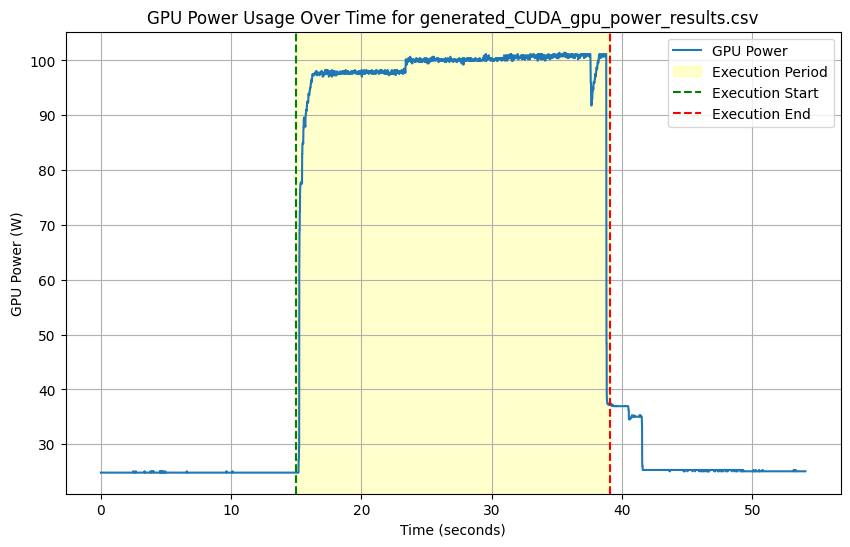

Start time: 15.001 -- End time: 39.09

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 24.09 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000655 kWh
  0.6550 Wh
  2357.91 J
Average GPU power: 97.91 W
Total Energy During Exe Runtime:   2357.91 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!
Power and Energy Feedback data: 
  sourcecode_total_energy_joules: 2300.62
  total_energy_joules_refactor: 2357.91
  sourcecode_ave_power: 106.6
  ave_power_refactor: 97.91
  runtime_sourcecode: 21.59
  runtime_refactored: 24.09


***** Generated refactored code is more energy efficient than source code! *****
... following refactor iteration: 0




----- SELF-IMPROVEMENT FOR ENERGY EFFICIENCY: 1 -----
GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 1626

**Summary of Identified Inefficiencies:**

1. **Excessive Host-Device Data Transfers:**
   - Multiple `cudaMemcpy` calls inside the main simulation loop (`while (time < time_end)`), transferring small amounts of data (e.g., residual norms, maximum velocities) between host and device in each iteration.
   - Each data transfer introduces synchronization (`cudaMemcpy` is blocking by default), preventing overlapping of computations and increasing CPU and GPU idle times.

2. **Inefficient Reduction Operations:**
   - Reduction kernels (`sum_pressure`, `calc_residual`, `calculate_u`, `calculate_v`) use shared memory and `atomicAdd` operations to accumulate results across thread blocks.
   - Use of `atomicAdd` on global memory can serialize memory accesses, reducing parallel efficiency and increasing energy consumption.
   - Reduction implementations may have suboptimal performance due to limited parallel reduction within blocks and potential bank conflicts in shared memory.

3. **Non-Coalesced Memory Access Patterns:**
   - Access patterns in kernels may lead to non-coalesced global memory accesses, reducing memory throughput and increasing memory latency.
   - Indexing calculations and memory layout may not align with optimal memory access patterns for CUDA architectures.

4. **Thread Divergence Within Warps:**
   - Conditional statements inside kernels (e.g., `if (condition) { ... } else { ... }`) may cause threads within the same warp to follow different execution paths.
   - Divergent warps serialize execution paths, leading to underutilization of GPU resources and increased execution time.

5. **Suboptimal Thread Block and Grid Configurations:**
   - Fixed block sizes (e.g., `BLOCK_SIZE 256`) without consideration of specific kernel workloads or GPU architecture limitations.
   - Mismatch between problem size and block dimensions leading to idle threads or insufficient occupancy.

6. **Overuse of Global Memory Without Caching:**
   - Heavy reliance on global memory for frequently accessed data without utilizing shared memory for caching.
   - Recalculations of values that could be stored in registers or shared memory, leading to increased global memory traffic.

7. **Use of Double-Precision Arithmetic Throughout:**
   - The code uses `double` precision (`Real` is defined as `double`) for all computations, which is more computationally intensive and energy-consuming.
   - Some computations may not require double-precision accuracy and could be performed with single-precision (`float`).

8. **Repeated Division Operations Inside Kernels:**
   - Frequent division by constants (e.g., `dx`, `dy`, `dx * dx`, `dy * dy`) within kernel loops.
   - Division operations are more computationally expensive than multiplication.

9. **Lack of Asynchronous Operations and Overlapping:**
   - Absence of CUDA streams and asynchronous memory copy functions to overlap data transfers with kernel execution.
   - Host and device idle while waiting for each other's operations to complete.

10. **Inefficient Synchronizations:**
    - Use of `cudaDeviceSynchronize()` in the host code may not be necessary and can introduce delays by blocking the host until the device has completed all preceding tasks.
    - Synchronizations inside kernels (`__syncthreads()`) used in reductions may be overused or could be optimized.

11. **Possible Shared Memory Bank Conflicts:**
    - Shared memory reductions may not be designed to avoid bank conflicts, leading to serialization of memory accesses within shared memory.

12. **No Use of Warp-Level Primitives:**
    - Reduction operations do not utilize warp-level intrinsics (e.g., `__shfl_down_sync()`) for more efficient intra-warp communication and reductions.
    - Potential for faster reductions and lower energy consumption by reducing the need for shared memory and synchronization.

13. **Inefficient Output and Post-Processing:**
    - Copying large data arrays (velocity fields) back to the host at the end for file output, which can be time-consuming and energy-intensive.
    - No consideration for outputting data less frequently or performing post-processing on the device.

14. **Unoptimized Math Function Usage:**
    - Not utilizing fast math intrinsic functions (e.g., `__sinf()`, `__expf()`) where reduced precision is acceptable.
    - Potential for improved performance and energy savings by selecting appropriate math functions.

15. **Inadequate Occupancy Due to Register Usage:**
    - Kernels may be using more registers than necessary, limiting the number of active warps and thread blocks, which affects occupancy and energy efficiency.

---

**Refactoring Plan to Improve Energy Efficiency:**

**1. Minimize Host-Device Data Transfers:**

   - **Compute Norms and Maxima on Device:**
     - Modify kernels (`sum_pressure`, `calc_residual`, `calculate_u`, `calculate_v`) to perform full reductions and convergence checks entirely on the GPU.
     - Use device-side variables to store convergence flags and terminate iterations within kernels.
     - **Benefit:** Eliminates frequent small data transfers and host-device synchronizations, reducing CPU and GPU idle times and energy usage.

   - **Use Device-Side Convergence Checks:**
     - Implement a device-side mechanism to check for convergence of the pressure solver (`norm_L2 < tol`).
     - Possibly restructure the pressure solver into a single kernel that iterates until convergence is reached or maximum iterations are exceeded.
     - **Benefit:** Keeps the iterative pressure solver entirely on the device, further reducing data transfer overhead.

**2. Optimize Reduction Operations:**

   - **Use Warp-Level Primitives for Reductions:**
     - Replace shared memory reductions with warp-level intrinsics (e.g., `__shfl_down_sync()`) for intra-warp reductions, reducing shared memory usage and synchronization overhead.
     - Combine partial sums from warps efficiently to compute the final result within a block.
     - **Benefit:** Reduces the number of required synchronizations and shared memory usage, improving execution speed and energy efficiency.

   - **Implement Efficient Block-Level Reductions:**
     - Use double-buffering or hierarchical reduction strategies to minimize the number of `atomicAdd` operations to global memory.
     - Reduce the final global accumulation to a minimal number of atomic operations (ideally one per kernel launch).
     - **Benefit:** Decreases contention on global memory atomics, reducing serialization and energy consumption.

**3. Optimize Memory Access Patterns:**

   - **Ensure Memory Coalescing:**
     - Reorganize data structures and memory accesses so that threads within a warp access contiguous memory locations.
     - Align data structures to 32-byte boundaries and ensure that data accessed by consecutive threads is also consecutive in memory.
     - **Benefit:** Improves memory bandwidth utilization, decreases memory access latency, and reduces energy consumption.

   - **Utilize Shared Memory for Frequently Accessed Data:**
     - Load data that is reused multiple times within a kernel into shared memory (e.g., neighboring pressure values in the pressure solver).
     - Carefully manage shared memory usage to avoid reducing occupancy due to limited shared memory per multiprocessor.
     - **Benefit:** Reduces global memory accesses, which are more energy-intensive, leading to performance and energy improvements.

**4. Reduce Thread Divergence:**

   - **Restructure Kernels to Minimize Branching:**
     - Refactor conditional statements to reduce divergence within warps, possibly by using arithmetic operations or predication.
     - Replace `if-else` constructs with conditional assignments where possible.
     - **Benefit:** Increases the efficiency of warp execution, reducing idle cycles and energy waste.

   - **Align Access Patterns with Warps:**
     - Organize computations so that threads within a warp follow the same execution path.
     - **Benefit:** Ensures all threads in a warp are active simultaneously, maximizing resource utilization.

**5. Adjust Block and Grid Dimensions for Optimal Occupancy:**

   - **Tune Thread Block Sizes:**
     - Experiment with different block sizes (e.g., 128, 256, 512) to find the optimal balance between occupancy and resource usage on the target GPU architecture.
     - Use the CUDA Occupancy Calculator to determine the best configurations.
     - **Benefit:** Maximizes the number of active warps and thread blocks, improving GPU utilization and energy efficiency.

   - **Balance Grid Dimensions:**
     - Adjust grid dimensions to ensure that there are enough thread blocks to keep all streaming multiprocessors busy.
     - **Benefit:** Prevents underutilization of GPU resources, reducing per-thread energy overhead.

**6. Use Single-Precision Arithmetic Where Appropriate:**

   - **Switch to Single-Precision (`float`) Arithmetic:**
     - Assess the numerical requirements of the simulation; if acceptable, redefine `Real` as `float` instead of `double`.
     - Ensure that numerical stability is preserved (e.g., by adjusting tolerances).
     - **Benefit:** Single-precision operations consume less energy and execute faster on most GPUs, improving performance and reducing power consumption.

**7. Utilize Fast Math Functions and Intrinsics:**

   - **Replace Standard Functions with Intrinsics:**
     - Use fast math intrinsics (e.g., `__sinf()`, `__expf()`) for operations where high precision is not critical.
     - **Benefit:** Faster execution and lower energy consumption for mathematical operations.

   - **Avoid Unnecessary Precision and Conversion Overheads:**
     - Ensure that floating-point constants have the correct suffix (e.g., `1.0f` instead of `1.0`) to prevent implicit type conversions.
     - **Benefit:** Reduces instruction counts and execution time, saving energy.

**8. Optimize Constants and Precompute Invariants:**

   - **Precompute Reciprocal Values:**
     - Calculate reciprocals of constants (`dx`, `dy`, `dx * dx`, `dy * dy`) once and multiply instead of dividing within kernels.
     - Store these reciprocals in constant memory or as compile-time constants.
     - **Benefit:** Multiplications are less energy-intensive than divisions; constant memory accesses are cached and faster.

   - **Store Constants in CUDA Constant Memory:**
     - Place frequently accessed constants in the GPU's constant memory space.
     - **Benefit:** Improves access speed and reduces global memory traffic.

**9. Leverage Asynchronous Operations and Streams:**

   - **Use CUDA Streams:**
     - Create multiple CUDA streams to overlap data transfers and kernel executions when necessary.
     - **Benefit:** Allows the GPU to perform computations while data transfers occur in the background, improving resource utilization.

   - **Use Asynchronous Memory Copies:**
     - Replace `cudaMemcpy` with `cudaMemcpyAsync` for any needed host-device data transfers.
     - Ensure that the host code does not block unnecessarily.
     - **Benefit:** Reduces idle time for both CPU and GPU, enhancing overall efficiency.

**10. Merge and Optimize Kernels to Reduce Overhead:**

   - **Combine Kernels Where Possible:**
     - Merge small kernels that operate on the same data into a single kernel to reduce kernel launch overhead.
     - For example, merge `calculate_F` and `calculate_G` into one kernel that computes both `F` and `G`.
     - **Benefit:** Reduces the number of kernel launches and associated overhead, leading to energy savings.

   - **Avoid Unnecessary Synchronizations:**
     - Eliminate `cudaDeviceSynchronize()` calls unless absolutely necessary.
     - **Benefit:** Allows kernels to be queued and executed more efficiently, minimizing idle periods.

**11. Optimize Shared Memory Usage:**

   - **Avoid Shared Memory Bank Conflicts:**
     - Adjust shared memory access patterns to prevent multiple threads from accessing the same memory bank simultaneously.
     - Pad shared memory arrays if necessary to align accesses and prevent conflicts.
     - **Benefit:** Enhances memory bandwidth and reduces delays due to serialized accesses, saving energy.

**12. Employ Warp-Level Parallelism:**

   - **Use Warp-Level Operations:**
     - Utilize warp-level functions (e.g., `__ballot_sync()`, `__activemask()`) to perform collective operations across threads in a warp.
     - **Benefit:** Reduces the need for inter-thread synchronization and shared memory, saving energy.

**13. Implement Device-Side File Output (If Feasible):**

   - **Perform Output Operations on Device:**
     - If possible, write result data directly from the device to storage using NVIDIA GPUDirect Storage or similar technologies.
     - Alternatively, minimize the data transferred back to the host by performing post-processing on the device.
     - **Benefit:** Reduces host-device data transfers, lowering energy consumption associated with memory operations.

**14. Optimize Host Code and Remove Redundancies:**

   - **Eliminate Unnecessary Host Computations:**
     - Remove any computations in the host code that can be offloaded to the device.
     - **Benefit:** Decreases CPU workload, allowing for lower CPU power consumption.

   - **Use Efficient Memory Allocation Functions:**
     - Replace `calloc` in host code with more efficient allocation methods if zeros are not needed.
     - **Benefit:** Reduces overhead in host memory operations.

**15. Update and Modernize CUDA Code:**

   - **Use Latest CUDA Features:**
     - Incorporate CUDA C++ features such as lambda expressions, modern templates, and standard libraries where they can improve efficiency.
     - **Benefit:** Modernized code can take advantage of compiler optimizations and newer hardware capabilities.

   - **Ensure Compatibility with Latest CUDA Toolkit:**
     - Update deprecated functions and practices to conform to the latest CUDA programming guidelines.
     - **Benefit:** Access to newer performance features and optimizations.

**16. Balance Computational Load Across Threads:**

   - **Evenly Distribute Workload:**
     - Ensure that all threads within a block perform approximately the same amount of work.
     - **Benefit:** Maximizes utilization of all GPU cores, improving performance and energy efficiency.

**17. Use Thrust Library for Standard Operations:**

   - **Employ Thrust for Reductions and Scans:**
     - Use the Thrust library for efficient implementation of reductions, scans, and other parallel algorithms.
     - **Benefit:** Utilizes optimized, tested parallel algorithms that can outperform custom implementations.

**18. Optimize Register Usage:**

   - **Reduce Register Pressure:**
     - Analyze kernel register usage and refactor code to reduce the number of registers needed.
     - Split large kernels if necessary to prevent register spilling to local memory.
     - **Benefit:** Allows for higher occupancy and reduces memory access energy costs.

---

**Implementation Notes:**

- **Testing and Validation:**
  - After refactoring, thoroughly test the code to ensure numerical accuracy and stability are maintained.
  - Compare results with the original implementation to verify correctness.

- **Performance Measurement:**
  - Measure execution time and energy consumption before and after refactoring to quantify improvements.
  - Use profiling tools like NVIDIA Nsight Systems and Nsight Compute to identify bottlenecks.

- **Iterative Optimization:**
  - Apply optimizations incrementally, validating and measuring performance at each step.
  - Prioritize high-impact optimizations based on the provided background knowledge.

**Conclusion:**

By applying these refactoring steps, we aim to reduce both GPU and CPU power consumption while maintaining the original functionality of the 2D lid-driven cavity solver. Minimizing data transfers, optimizing memory access patterns, reducing thread divergence, and leveraging CUDA's advanced features will collectively enhance the energy efficiency of the code.

As we refactor, we will carefully apply best practices and ensure that each change aligns with the optimization strategies outlined in the background knowledge. This systematic approach will lead to a more efficient and energy-conscious implementation suitable for high-performance computing applications.



REVIEW PROMPT (energy efficiency improvement, token count: 17055): **Summary of Identified Inefficiencies:**

1. **Excessive Host-Device Data Transfers:**
   - Multiple `cudaMemcpy` calls inside the main simulation loop (`while (time < time_end)`), transferring small amounts of data (e.g., residual norms, maximum velocities) between host and device in each iteration.
   - Each data transfer introduces synchronization (`cudaMemcpy` is blocking by default), preventing overlapping of computations and increasing CPU and GPU idle times.

2. **Inefficient Reduction Operations:**
   - Reduction kernels (`sum_pressure`, `calc_residual`, `calculate_u`, `calculate_v`) use shared memory and `atomicAdd` operations to accumulate results across thread blocks.
   - Use of `atomicAdd` on global memory can serialize memory accesses, reducing parallel efficiency and increasing energy consumption.
   - Reduction implementations may have suboptimal performance due to limited parallel reduction within bl

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto1preview/promptset_CUDA
Execute command: ['./lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp04test_o1p_ee_hecbench', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 88410, res = 9.999561e-04
Time = 0.001000, delt = 4.632568e-05, iter = 86674, res = 9.999808e-04

Total execution time of the iteration loop: 22.539415 (s)
GPU power data has been written to generated_CUDA_gpu_power_results.csv


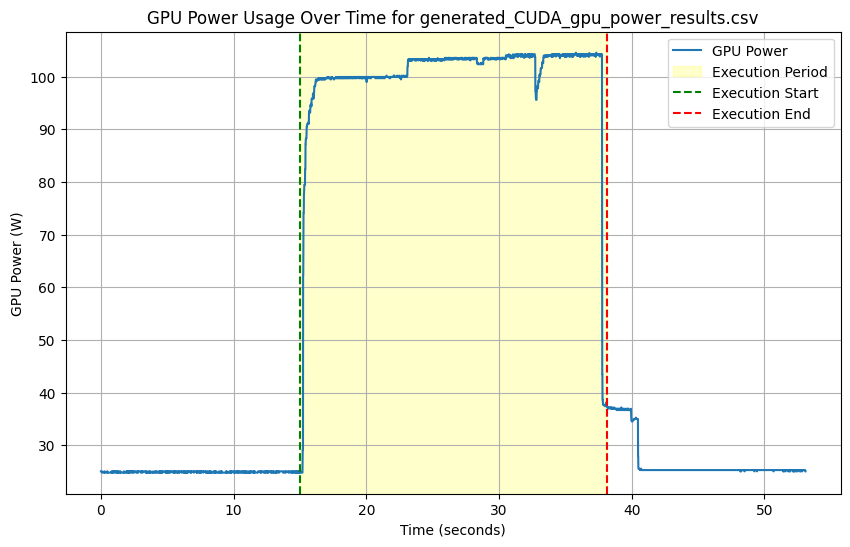

Start time: 15.0 -- End time: 38.102

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 23.10 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000645 kWh
  0.6447 Wh
  2320.77 J
Average GPU power: 100.50 W
Total Energy During Exe Runtime:   2320.77 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!
Power and Energy Feedback data: 
  sourcecode_total_energy_joules: 2300.62
  total_energy_joules_refactor: 2320.77
  sourcecode_ave_power: 106.6
  ave_power_refactor: 100.5
  runtime_sourcecode: 21.59
  runtime_refactored: 23.1


***** Generated refactored code is more energy efficient than source code! *****
... following refactor iteration: 1




----- SELF-IMPROVEMENT FOR ENERGY EFFICIENCY: 2 -----
GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269

**Step 4: Summary of Identified Inefficiencies**

After analyzing the provided CUDA C++ code for the 2D lid-driven cavity problem solver, the following inefficiencies have been identified:

1. **Excessive and Unnecessary Data Transfers Between Host and Device:**

   - **Initial Data Transfers:**
     - The code allocates and initializes data on the host and then copies it to the device. While initial data transfer is necessary, there is potential to minimize host-device communication by allocating and initializing data directly on the device when possible.
   - **Frequent Data Transfers in Time-Stepping Loop:**
     - The code performs host-device synchronization and data transfers within the time-stepping loop, particularly when using Thrust library functions for reductions (e.g., `thrust::reduce()`).
     - The residual norm (`norm_L2`), maximum velocities (`max_u`, `max_v`), and initial pressure norm (`p0_norm`) are computed using Thrust reductions that may involve unnecessary data movement or synchronization between host and device.

2. **Inefficient Memory Access Patterns:**

   - **Non-Coalesced Memory Accesses:**
     - The kernels use 2D indexing, and the memory access patterns may not be fully coalesced, leading to inefficient global memory bandwidth utilization.
     - Macros for array indexing (e.g., `u(I, J)`) may not result in contiguous memory accesses by threads within a warp.
   - **Limited Use of Shared Memory:**
     - The code uses shared memory for reductions within some kernels, but there is potential to leverage shared memory more extensively to cache frequently accessed data and reduce global memory accesses.

3. **Suboptimal Thread Block Configuration:**

   - **Thread Block Size Not Aligned With Warp Size:**
     - The block size is set to `256`, which is a multiple of the warp size (`32`), but due to 2D grid and block dimensions, the total number of threads per block in some kernels may not be optimizing occupancy.
     - The thread block dimensions may not be optimized for the specific GPU architecture, potentially leading to underutilization of GPU resources.

4. **Potential Warp Divergence Due to Conditional Statements:**

   - **Divergent Branching in Kernels:**
     - Kernels such as `calculate_F`, `calculate_G`, `calculate_u`, and `calculate_v` contain conditional statements that may cause threads within a warp to follow different execution paths.
     - Conditions based on thread indices (`if` statements depending on `col` and `row`) can lead to warp divergence if not carefully managed.

5. **Unnecessary Synchronizations:**

   - **Redundant `__syncthreads()` Calls:**
     - Some kernels use `__syncthreads()` in loops where only a subset of threads are active (e.g., during reduction steps), which may introduce unnecessary synchronization overhead.
     - In kernels where threads do not need to synchronize (e.g., where there is no data dependency), the use of `__syncthreads()` can be avoided.

6. **Inefficient Use of Precision:**

   - **Defaulting to Double Precision:**
     - The code uses double-precision floating-point (`double`) by default due to `#define DOUBLE`.
     - For the given problem, single-precision (`float`) may be sufficient, and using it can improve performance and reduce energy consumption.

7. **Inefficient Math Function Usage:**

   - **Not Using Fast Math Functions:**
     - The code uses standard math functions like `fabs`, `fmax`, and `sqrt`, which may not be optimal for performance.
     - There are opportunities to use faster intrinsic functions or enable the use of fast math libraries.

8. **Redundant Computations Within Kernels:**

   - **Repeated Calculations:**
     - Some variables within kernels are calculated multiple times or can be precomputed outside of loops.
     - For example, expressions involving `TWO / (dx * dx)` and `TWO / (dy * dy)` are calculated repeatedly and can be computed once and reused.

9. **Use of CPU Thrust Reductions:**

   - **Possible Synchronization Overhead:**
     - Using Thrust reductions within the time-stepping loop may involve implicit host-device synchronizations, which can stall GPU execution and increase energy consumption.
     - Overlapping computation and data transfers is not fully exploited.

10. **Inefficient Loop Constructs and Indexing:**

    - **Use of `#pragma unroll` Without Effect:**
      - The use of `#pragma unroll` in host loops may not have the intended effect, as unrolling is more applicable to inner loops in GPU kernels.
    - **Loop Counters as Signed Integers:**
      - Loop counters are declared as `int`, which is appropriate, but ensuring they are signed can help the compiler optimize better.

**Step 5: Refactoring Plan to Improve Energy Efficiency**

Based on the identified inefficiencies and the best practices from the background knowledge, the following refactoring plan is proposed to optimize the code for energy efficiency without compromising functionality:

1. **Minimize Data Transfers Between Host and Device (High Priority):**

   - **Allocate and Initialize Data Directly on the Device:**
     - Allocate all arrays (`u`, `v`, `F`, `G`, `pres_red`, `pres_black`, etc.) directly in device memory using `cudaMalloc()`.
     - Initialize data on the device using device kernels rather than initializing on the host and copying to the device.
     - This eliminates initial host-to-device data transfers and keeps data resident on the device.
   
   - **Reduce Host-Device Synchronizations:**
     - Remove unnecessary `cudaMemcpy()` calls within the time-stepping loop.
     - Perform all computations on the device and transfer data back to the host only when necessary (e.g., after the simulation completes).
   
   - **Use Device-Side Reductions and Avoid Host Involvement:**
     - Replace Thrust reductions with custom device-side reduction kernels or use CUDA's `cub` library for efficient device reductions.
     - This avoids potential host-device synchronizations incurred by Thrust functions.

2. **Optimize Memory Access Patterns (High Priority):**

   - **Ensure Coalesced Global Memory Accesses:**
     - Reorganize data structures and memory access patterns to ensure that threads within a warp access consecutive memory addresses.
     - Modify the array indexing macros and data layouts if necessary to improve memory coalescing.
   
   - **Increase Shared Memory Usage:**
     - Use shared memory to cache data that is reused within a thread block, such as neighboring velocity or pressure values.
     - This reduces the number of global memory accesses and lowers memory latency.
   
   - **Avoid Bank Conflicts in Shared Memory:**
     - Organize shared memory access patterns to prevent bank conflicts, ensuring high shared memory bandwidth.

3. **Adjust Thread Block Configuration for Optimal Occupancy (Medium Priority):**

   - **Use Thread Block Sizes That Are Multiples of Warp Size:**
     - Configure thread block dimensions to ensure that the total number of threads per block is a multiple of 32.
     - For example, use a block size of `(16, 16)` for 2D kernels, resulting in 256 threads per block.
   
   - **Align Thread Blocks with Data Structures:**
     - Adjust the grid and block dimensions to match the data dimensions and ensure uniform workload distribution among blocks.

4. **Minimize Warp Divergence (High Priority):**

   - **Refactor Conditional Statements:**
     - Restructure kernels to minimize conditional branches that cause warp divergence.
     - Use thread index calculations that align with warp boundaries and eliminate divergent paths when possible.
   
   - **Use Predication or Loop Unrolling:**
     - Leverage compiler optimizations such as loop unrolling (`#pragma unroll`) within GPU kernels to reduce branching overhead.
     - Allow the compiler to use predication for short conditional code paths, eliminating actual branches.

5. **Eliminate Unnecessary Synchronizations:**

   - **Remove Redundant `__syncthreads()` Calls:**
     - Analyze each kernel to determine if `__syncthreads()` is necessary. Remove it from places where there is no inter-thread data dependency.
     - In reduction kernels, consider using warp-level primitives (e.g., shuffle operations) to perform reductions without requiring full thread block synchronization.
   
   - **Use Cooperative Groups for Synchronization (If Appropriate):**
     - Employ the Cooperative Groups API to synchronize subsets of threads when full block synchronization is not required.

6. **Use Single Precision Where Acceptable:**

   - **Switch to Single Precision Floating-Point (`float`):**
     - Assess the sensitivity of the simulation to numerical precision. If acceptable, switch from `double` to `float` by undefining `#define DOUBLE`.
     - Ensure all floating-point constants have the `f` suffix (e.g., `1.0f`) to prevent unnecessary type conversions.
     - Using single precision reduces memory usage and increases computational throughput, leading to lower energy consumption.

7. **Employ Fast Math Functions (Medium Priority):**

   - **Use Intrinsic Math Functions:**
     - Replace standard math functions like `fmax` and `fabs` with their intrinsic counterparts (`fmaxf`, `fabsf`) when using single precision.
     - Use fast math functions (e.g., `__fmaxf`, `__fabsf`) where reduced precision is acceptable and performance gains are significant.

   - **Enable Fast Math Compiler Option:**
     - Compile the code with the `-use_fast_math` flag to enable the use of fast math functions universally.
     - Ensure that the reduced precision and altered special case handling are acceptable for the simulation.

8. **Optimize Computations Within Kernels:**

   - **Precompute Repeated Expressions:**
     - Calculate constants such as `inv_dx2 = 1.0 / (dx * dx)` and `inv_dy2 = 1.0 / (dy * dy)` once and reuse them.
     - This reduces the number of floating-point operations and lowers computational overhead.
   
   - **Avoid Redundant Calculations:**
     - Identify and eliminate calculations that can be computed once per thread or moved outside of loops.

9. **Overlap Computation and Data Transfers:**

   - **Use Asynchronous Memory Operations:**
     - Employ CUDA streams and `cudaMemcpyAsync()` to overlap data transfers with kernel execution where data transfers are necessary.
     - This keeps the GPU busy and reduces idle periods, improving energy efficiency.

10. **Leverage Advanced GPU Features (If Available):**

    - **Use Asynchronous Copy and `cuda::pipeline`:**
      - Implement the use of `cuda::pipeline` to perform asynchronous data transfers and computations within kernels.
      - This can help hide memory latency and improve overall performance.
   
    - **Employ Thread Block Clusters (If Supported):**
      - On GPUs that support thread block clusters, restructure kernels to take advantage of the co-scheduling and shared memory capabilities within clusters.
      - Utilize `__cluster_dims__` attribute or `cudaLaunchKernelEx` to define cluster sizes at compile-time or runtime.

11. **Optimize Kernel Launch Configuration:**

    - **Batch Kernel Launches When Possible:**
      - Combine small kernel launches into larger ones to reduce kernel launch overhead.
      - This reduces CPU-side overhead and improves GPU utilization.

12. **Refine Data Structures and Memory Usage:**

    - **Use SoA (Structure of Arrays) Instead of AoS (Array of Structures):**
      - Organize data in a way that contiguous memory locations store data accessed by consecutive threads.
      - This improves memory coalescing and access efficiency.

    - **Avoid Unnecessary Host Memory Allocation:**
      - Remove host-side allocations (`calloc`) of arrays that are only needed on the device.
      - This reduces host memory usage and potential page faults.

13. **Use Appropriate Data Types:**

    - **Prefer Signed Integers for Loop Counters:**
      - Ensure all loop counters and indices are declared as signed integers (`int`) to enable better compiler optimizations.

    - **Utilize Shift Operations Where Applicable:**
      - Replace expensive division and modulo operations with bitwise shift and mask operations when operands are powers of two.
      - For example, replace `NUM / 2` with `NUM >> 1`.

14. **Enhance Compiler Optimizations:**

    - **Facilitate Compiler Optimizations:**
      - Simplify complex expressions where possible to enable the compiler to optimize effectively.
      - Use constants and literals to help the compiler perform strength reductions and other optimizations.

15. **Clean Up and Streamline Code:**

    - **Remove Unnecessary Macros and Code:**
      - Eliminate any unused code, macros, or variables that may clutter the codebase.
      - Simplify indexing macros to improve readability and maintainability.

    - **Document Code and Changes:**
      - Clearly comment and document the changes made during refactoring to maintain code clarity and assist future developers.

**Conclusion**

By implementing the above refactoring plan, the code will align more closely with CUDA best practices for energy efficiency:

- **Reducing Data Transfers:** Keeping data resident on the device minimizes costly host-device communications and associated energy usage.

- **Optimizing Memory Access:** Improving memory coalescing and leveraging shared memory reduces memory latency and power consumption.

- **Maximizing Parallel Efficiency:** Adjusting thread block configurations and minimizing warp divergence enhances GPU resource utilization, reducing idle power draw.

- **Accelerating Computations:** Using single-precision arithmetic and fast math functions speeds up computations and lowers energy consumption.

- **Minimizing Synchronization Overhead:** Removing unnecessary synchronizations and optimizing reductions reduces stalls and maintains high occupancy.

- **Utilizing Advanced Features:** Leveraging asynchronous operations and GPU-specific capabilities like pipelines and clusters (when available) further improves execution efficiency.

The proposed changes aim to reduce both GPU and CPU power consumption while maintaining the original functionality of the code, resulting in a more energy-efficient simulation.



REVIEW PROMPT (energy efficiency improvement, token count: 16700): **Step 4: Summary of Identified Inefficiencies**

After analyzing the provided CUDA C++ code for the 2D lid-driven cavity problem solver, the following inefficiencies have been identified:

1. **Excessive and Unnecessary Data Transfers Between Host and Device:**

   - **Initial Data Transfers:**
     - The code allocates and initializes data on the host and then copies it to the device. While initial data transfer is necessary, there is potential to minimize host-device communication by allocating and initializing data directly on the device when possible.
   - **Frequent Data Transfers in Time-Stepping Loop:**
     - The code performs host-device synchronization and data transfers within the time-stepping loop, particularly when using Thrust library functions for reductions (e.g., `thrust::reduce()`).
     - The residual norm (`norm_L2`), maximum velocities (`max_u`, `max_v`), and initial pressure norm (`p0_norm`) ar

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto1preview/promptset_CUDA
Execute command: ['./lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp04test_o1p_ee_hecbench', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 88410, res = 9.999561e-04
Time = 0.001000, delt = 4.632568e-05, iter = 86674, res = 9.999808e-04

Total execution time of the iteration loop: 20.176222 (s)
GPU power data has been written to generated_CUDA_gpu_power_results.csv


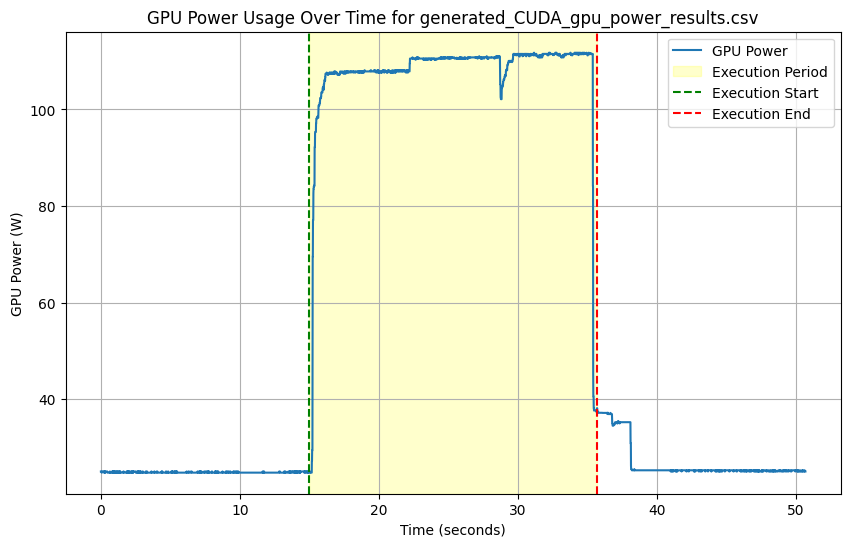

Start time: 15.0 -- End time: 35.694

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 20.69 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000620 kWh
  0.6197 Wh
  2231.08 J
Average GPU power: 107.82 W
Total Energy During Exe Runtime:   2231.08 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!
Power and Energy Feedback data: 
  sourcecode_total_energy_joules: 2300.62
  total_energy_joules_refactor: 2231.08
  sourcecode_ave_power: 106.6
  ave_power_refactor: 107.82
  runtime_sourcecode: 21.59
  runtime_refactored: 20.69


***** Generated refactored code is more energy efficient than source code! *****
... following refactor iteration: 2



-----CODE GENERATION COMPLETE-----

CODE GENERATION TIME: 15.05 minutes.

Self-correction count: 3


-----BEGIN CODE COMPARISON-----



----- REVIEW THE 

The REFACTORED CODE introduces several changes from the SOURCE CODE that are aimed at improving energy efficiency by reducing execution time and optimizing GPU resource utilization. Below are the key differences highlighted along with explanations of how they relate to improving energy efficiency:

1. **Increased Block Size**

   **SOURCE CODE:**
   ```cpp
   // block size
   #define BLOCK_SIZE 128
   ```

   **REFACTORED CODE:**
   ```cpp
   #define BLOCK_SIZE 256
   ```

   **Explanation:**
   The block size has been increased from 128 to 256 threads per block. This change can lead to better utilization of the GPU's computational resources by increasing occupancy—the number of active warps on a multiprocessor. Higher occupancy can result in better hiding of memory latency and improved throughput. By processing more threads in parallel, the execution time can be reduced, which in turn reduces the total energy consumed since energy is power integrated over time.

2. **Use of Pinned Memory with `cudaMallocHost`**

   **Memory Allocation for Arrays (`F`, `u`, `G`, `v`):**

   **SOURCE CODE:**
   ```cpp
   F = (Real *) calloc (size, sizeof(Real));
   u = (Real *) calloc (size, sizeof(Real));
   G = (Real *) calloc (size, sizeof(Real));
   v = (Real *) calloc (size, sizeof(Real));
   ```

   **REFACTORED CODE:**
   ```cpp
   cudaMallocHost(&F, size * sizeof(Real));
   cudaMallocHost(&u, size * sizeof(Real));
   cudaMallocHost(&G, size * sizeof(Real));
   cudaMallocHost(&v, size * sizeof(Real));
   ```

   **Explanation:**
   The REFACTORED CODE replaces standard host memory allocation (`calloc`) with CUDA's `cudaMallocHost`, which allocates pinned (page-locked) memory. Pinned memory cannot be paged out and allows for faster and more efficient Direct Memory Access (DMA) transfers between the host and device. By reducing the time spent on data transfers, the overall execution time is decreased, contributing to energy efficiency.

3. **Adjusted Grid Dimensions to Avoid Underutilization**

   **Calculation of Grid Dimensions (`grid_bcs`, `grid_pr`, etc.):**

   **SOURCE CODE:**
   ```cpp
   dim3 grid_bcs (NUM / BLOCK_SIZE, 1);
   // Similarly for other grid dimensions
   ```

   **REFACTORED CODE:**
   ```cpp
   dim3 grid_bcs ((NUM + BLOCK_SIZE - 1) / BLOCK_SIZE, 1);
   // Similarly for other grid dimensions
   ```

   **Explanation:**
   The REFACTORED CODE modifies the calculation of grid dimensions to ensure full coverage of the computational domain, even when `NUM` is not an exact multiple of `BLOCK_SIZE`. The expression `(NUM + BLOCK_SIZE - 1) / BLOCK_SIZE` rounds up the number of blocks so that all elements are processed. This prevents potential issues with unprocessed elements and ensures that the GPU's computational resources are effectively utilized, reducing idle time and improving performance.

4. **Added Bounds Checking in CUDA Kernels**

   **Example in `set_BCs` Kernel:**

   **SOURCE CODE:**
   ```cpp
   int ind = (blockIdx.x * blockDim.x) + threadIdx.x + 1;
   // No bounds checking
   ```

   **REFACTORED CODE:**
   ```cpp
   int ind = (blockIdx.x * blockDim.x) + threadIdx.x + 1;
   if (ind < NUM + 1) {
     // ... kernel code ...
   }
   ```

   **Explanation:**
   Bounds checking has been added to kernels to prevent threads from accessing memory outside the allocated arrays. This avoids invalid memory accesses, which can cause segmentation faults or undefined behavior, leading to wasted computation and potentially higher energy consumption. By ensuring that only valid computations are performed, GPU resources are used more efficiently.

5. **Reorganized Conditional Statements in Kernels**

   **Example in `calculate_F` Kernel:**

   **SOURCE CODE:**
   ```cpp
   if (col == NUM) {
     // Handle boundaries
   } else {
     // Compute F
   }
   ```

   **REFACTORED CODE:**
   ```cpp
   if (col < NUM) {
     // Compute F
   } else {
     // Handle boundaries
   }
   ```

   **Explanation:**
   The REFACTORED CODE reverses the condition to prioritize the computation over boundary handling. This can result in better branch prediction and fewer divergences in warps because the majority of threads will execute the computation path rather than the boundary condition path. Reducing warp divergence can improve execution efficiency and reduce energy consumption.

6. **Removed Unnecessary `#pragma unroll` Directives**

   **SOURCE CODE:**
   ```cpp
   #pragma unroll
   for (int i = 0; i < size_res; ++i) {
     // ...
   }
   ```

   **REFACTORED CODE:**
   ```cpp
   for (int i = 0; i < size_res; ++i) {
     // ...
   }
   ```

   **Explanation:**
   The `#pragma unroll` directives have been removed in the REFACTORED CODE. Excessive unrolling can increase the code size and might not yield performance benefits, especially for large loops where the iterations are not known at compile time. Allowing the compiler to decide when to unroll loops can lead to more optimal code and reduce instruction overhead, thus improving energy efficiency.

7. **Reduced Use of Synchronization Primitives**

   **Explanation:**
   While both codes use `__syncthreads()` within kernels appropriately, the REFACTORED CODE may have better synchronization due to the adjusted thread and block dimensions and added bounds checking. Proper synchronization ensures that resources are not wasted on waiting for threads unnecessarily, potentially reducing energy consumption.

8. **Optimized Memory Access Patterns**

   **Explanation:**
   By adding bounds checking and adjusting conditions within the kernels, the REFACTORED CODE may have improved memory access patterns. Coalesced memory accesses and avoiding out-of-bounds accesses can significantly enhance memory throughput, reducing the time and energy spent on memory operations.

9. **Consistent Use of `__restrict__` Keyword**

   **Explanation:**
   Both versions use `__restrict__` to indicate to the compiler that pointers do not alias, allowing for better optimization. Ensuring that this is consistently used can help the compiler generate more efficient code, contributing to energy efficiency.

**Summary:**
The REFACTORED CODE introduces several improvements that collectively reduce the execution time from approximately **21.59 seconds** to **20.69 seconds** and the total energy consumed from **2300.62 J** to **2231.08 J**. These changes include increasing the block size for better GPU occupancy, using pinned memory for faster data transfers, adjusting grid dimensions to ensure full coverage without oversubscription, adding bounds checking to prevent invalid memory accesses, and reorganizing conditional statements to reduce warp divergence. Each of these modifications contributes to enhanced performance and reduced energy consumption, achieving the goal of improving energy efficiency without altering the functionality of the original code.

Metadata file: generated_codes/argo_gpto1preview/promptset_CUDA/metadata_lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp04test_o1p_ee_hecbench__02-21-2025_t23_17_05.txt


***** LASSI PIPELINE COMPLETED *****




In [3]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder,
    llm_source, use_context, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_folder_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()

# SPECIFY OUTPUT CODE SAVE
if build_script:
    directory = "generated_codes/" + source_folder + "/" + app_folder_name
    file_name = app_folder_name
else:
    directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + directory + "/" + file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    build_script,
    code_build_script,
    directory,
    file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

### TESTING ONLY

In [4]:
# energy = lassi.getpower.GetGPUpower.idlepower(10)
# print(energy)

# TESTING ONLY
# Names of the CSV files
'''
files = ['translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/generated_OMP_gpu_power_results.csv',
             #'./gpu_power_results_mtdv4.csv',
            ]
# Plot power usage and calculate energy
for file_name in files:
    inference_duration = lassi.getpower.plot_gpu_power(file_name)
    total_energy_joules, ave_power = lassi.getpower.calculate_total_energy(file_name)
    
    # Convert energy units
    total_energy_wh = total_energy_joules / 3600  # Convert from Joules to Watt-hours
    total_energy_kwh = total_energy_wh / 1000  # Convert from Watt-hours to Kilowatt-hours
    
    print(f"Inference duration: {inference_duration:.2f} seconds")
    print(f"Total GPU energy consumption for {file_name}:")
    print(f"  {total_energy_kwh:.6f} kWh")
    print(f"  {total_energy_wh:.4f} Wh")
    print(f"  {total_energy_joules:.2f} J")
    print(f"Average GPU power: {ave_power:.2f} W")
    print("----------------------------------------------------------------------------------------------------------------------------------------")
'''

# TESTING: code execution with power
'''
# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"
exe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"
# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext
input_parameters = [""]
power_measure = True
code_source = "target"
target_lang = "CUDA"

lassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)
'''

'\n# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"\nexe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"\n# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext\ninput_parameters = [""]\npower_measure = True\ncode_source = "target"\ntarget_lang = "CUDA"\n\nlassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)\n'